# Sleep Duration and First-Year GPA: Does the Association Vary Across the Sleep Range?
### Main analysis of the thesis (reproduces every number, table and figure in the report)

**Anass Maata** · BSc CSAI, Tilburg University · Supervisor: Dr. Silvy Collin

**Research question.** *To what extent does the association between objectively measured sleep duration and end-of-term GPA vary across the observed sleep-duration range after accounting for previous academic performance?*

**Approach in one sentence.** Estimate the adjusted sleep–GPA association as a continuous curve with a GAM (Fig. 2, the main result), compare it with a straight line, and summarize the curve with GPA differences per extra hour between 5 and 8 h, where most students are (Table II).

**The three questions from the poster:** *What shape does the association have?* → Fig. 2 · *Where is it strongest?* → the one-hour differences · *Is one straight line good enough?* → the key comparison K and the residual check.

| Step | What happens | Report |
|---|---|---|
| 1 | Load and check the data | Methods III-A |
| 2 | Describe the 634 students and where sleep is concentrated | Table I, Fig. 1 |
| 3 | Fit the linear model and the GAM (both adjust for previous GPA and cohort) | Methods III-C |
| 3b | Check: does the linear model reproduce Creswell et al.'s slope of about 0.07? | Results IV-A |
| 4 | GPA differences for 5→6, 6→7 and 7→8 h, and the key comparison | Table II |
| 5 | Uncertainty with a bootstrap | Table II |
| 6 | Sensitivity analysis: without the two students who sleep less than 4 h | Table II, Fig. 2 |
| 6a | Why both lower bounds of the key comparison are about zero | Results IV-C |
| 6b | Residual check: where does the straight line miss? | Results IV-A |
| 7 | Does the pattern depend on one cohort? | Fig. 3 |
| 8 | Short secondary check: prediction for a cohort the model has not seen | Results IV-E |

**How to run.** Put this notebook next to `cmu-sleep.csv`, open it in VS Code and click *Run All*. The first run takes about 5–10 minutes (two bootstraps). Results are cached in `output/cache/`, so later runs take under a minute. Figures and tables are saved in `output/figures/` and `output/tables/`.

Everything here is an **association** in observational data, never an effect of sleep.

## 0. Setup
If a package is missing, remove the `#` in the next cell, run it once and restart the kernel.

In [ ]:
# %pip install pandas numpy scipy statsmodels pygam matplotlib

In [2]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import scipy, statsmodels, matplotlib, pygam
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
from pygam import LinearGAM, s, l, f

# pyGAM prints long warnings about its own p-values. We do not use them; we use the bootstrap instead.
warnings.filterwarnings("ignore", module="pygam")

print(f"Python      {sys.version.split()[0]}")
for name, mod in [("numpy", np), ("pandas", pd), ("scipy", scipy), ("statsmodels", statsmodels),
                  ("pygam", pygam), ("matplotlib", matplotlib)]:
    print(f"{name:<11} {mod.__version__}")

Python      3.14.4
numpy       2.4.6
pandas      3.0.3
scipy       1.16.3
statsmodels 0.15.0
pygam       0.12.0
matplotlib  3.11.2


### Settings (every choice the report mentions is set here)

| Setting | Value | Why |
|---|---|---|
| `SEED` | 2026 | The bootstrap gives the same result every run. |
| `B` | 1,000 | Number of bootstrap samples; common for 95% intervals. |
| `N_SPLINES` | 15 | Building blocks of the sleep curve. Set generously: the penalty decides how wiggly the curve becomes. |
| `LAM_GRID` | 33 values, 0.001 to 100,000 | Candidate penalty strengths; GCV picks one. A huge penalty gives a straight line. |
| `TINY` | 0.000001 | (Practically) no penalty for previous GPA and cohort, so they are adjusted for exactly like in the linear model. |
| `STEPS` | 5, 6, 7, 8 h | The one-hour steps we compare. Most students sleep 5–8 h. |
| `GRID` | 4.5–8.5 h | Range for the plotted curves (about 98% of students). |

In [3]:
DATA_PATH = Path("cmu-sleep.csv")
OUT = Path("output")
FIG, TAB, CACHE = OUT / "figures", OUT / "tables", OUT / "cache"
for folder in (FIG, TAB, CACHE):
    folder.mkdir(parents=True, exist_ok=True)

SEED = 2026
B = 1000
N_SPLINES = 15
LAM_GRID = np.logspace(-3, 5, 33)
TINY = 1e-6
STEPS = np.array([5.0, 6.0, 7.0, 8.0])
GRID = np.linspace(4.5, 8.5, 81)
USE_CACHE = True         # set to False to force the bootstraps to run again

# Figures sized for one column of the IEEE template (3.5 inch), 8-point serif labels
plt.rcParams.update({
    "figure.dpi": 150, "savefig.dpi": 300,
    "font.family": "serif", "font.serif": ["Times New Roman", "Times", "Nimbus Roman", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix", "pdf.fonttype": 42,
    "font.size": 8, "axes.labelsize": 8, "legend.fontsize": 7, "xtick.labelsize": 7, "ytick.labelsize": 7,
    "axes.linewidth": 0.6, "lines.linewidth": 1.2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.4,
})
C_GAM, C_LIN = "#2a78d6", "#eb6834"          # blue = GAM, orange = linear model
C_NEUTRAL, C_SPARSE, C_TEXT = "#8f8e88", "#f1f0ec", "#52514e"
C_COHORTS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6"]

def save_fig(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")
    fig.savefig(FIG / f"{name}.pdf", bbox_inches="tight")

def save_table(table, name):
    table.to_csv(TAB / f"{name}.csv")

## 1. Load and check the data
Public dataset of Creswell et al. (2023), CMU Statistics & Data Science Data Repository ("Nightly sleep time and GPA in first-years"). One row = one first-year student.

| Column | Role | Meaning |
|---|---|---|
| `TotalSleepTime` | predictor | Average nightly sleep (main sleep episode), Fitbit, about one month early in the term. Minutes → hours. |
| `term_gpa` | outcome | GPA of that term (0–4), official records. |
| `cum_gpa` | adjustment | GPA before that term ("previous GPA"). |
| `cohort` | adjustment | Which of the five study samples the student belongs to. |

In [4]:
raw = pd.read_csv(DATA_PATH, encoding="utf-8-sig")   # 'utf-8-sig' removes an invisible character at the start of the file

COHORT_INFO = {   # cohort -> (study, university, term), from the CMU repository page and Creswell et al.
    "lac2": ("1", "Carnegie Mellon", "Spring 2018"),
    "uw1":  ("2", "Univ. of Washington", "Spring 2018"),
    "uw2":  ("3", "Univ. of Washington", "Spring 2019"),
    "nh":   ("4", "Notre Dame", "Spring 2016"),
    "lac1": ("5", "Carnegie Mellon", "Spring 2017"),
}

df = raw[["subject_id", "study", "cohort", "TotalSleepTime", "cum_gpa", "term_gpa"]].copy()
df["sleep_h"] = df["TotalSleepTime"] / 60          # minutes -> hours

core = ["sleep_h", "cum_gpa", "term_gpa", "cohort"]
print(f"Students: {len(df)}")
print(f"Missing values in the core variables: {int(df[core].isna().sum().sum())}")
print(f"Duplicate students (same study and ID): {int(df.duplicated(['study', 'subject_id']).sum())}")
assert df[core].notna().all().all()
assert df["term_gpa"].between(0, 4).all() and df["cum_gpa"].between(0, 4).all()
df[["sleep_h", "cum_gpa", "term_gpa"]].describe().round(2)

Students: 634
Missing values in the core variables: 0
Duplicate students (same study and ID): 0


,sleep_h,cum_gpa,term_gpa
count,634.00,634.00,634.00
mean,6.62,3.47,3.45
std,0.85,0.44,0.50
min,3.25,1.21,0.35
25%,6.12,3.23,3.23
50%,6.67,3.56,3.56
75%,7.17,3.79,3.81
max,9.79,4.00,4.00


**Preprocessing:** sleep is converted to hours; nothing else is changed. No students are removed: there are no missing values, all GPAs are between 0 and 4, and the extreme sleep values are possible, not errors. The two students below 4 h are examined separately in step 6.

## 2. Describe the students (Table I, Fig. 1)

In [5]:
def describe(d):
    return pd.Series({
        "n": len(d),
        "Sleep mean (h)": d["sleep_h"].mean(), "Sleep SD (h)": d["sleep_h"].std(),
        "Previous GPA mean": d["cum_gpa"].mean(), "Term GPA mean": d["term_gpa"].mean(),
        "Term GPA = 4.0 (%)": 100 * (d["term_gpa"] == 4).mean(),
    })

table1 = pd.concat({**{c: describe(d) for c, d in df.groupby("cohort")}, "All": describe(df)}, axis=1)
save_table(table1, "table1_descriptives")
print("SD previous GPA:", round(df["cum_gpa"].std(), 2), "| SD term GPA:", round(df["term_gpa"].std(), 2))
print(df[["sleep_h", "cum_gpa", "term_gpa"]].corr().round(2))
table1.round(2)

SD previous GPA: 0.44 | SD term GPA: 0.5
          sleep_h  cum_gpa  term_gpa
sleep_h      1.00     0.11      0.20
cum_gpa      0.11     1.00      0.64
term_gpa     0.20     0.64      1.00


,lac1,lac2,nh,uw1,uw2,All
n,131.00,77.00,147.00,140.00,139.00,634.00
Sleep mean (h),6.53,6.32,6.42,6.88,6.83,6.62
Sleep SD (h),0.78,0.90,0.83,0.85,0.78,0.85
Previous GPA mean,3.33,3.51,3.64,3.48,3.37,3.47
Term GPA mean,3.28,3.48,3.66,3.49,3.33,3.45
Term GPA = 4.0 (%),13.74,22.08,6.12,3.57,3.60,8.52


In [6]:
bands = pd.cut(df["sleep_h"], [0, 5, 6, 7, 8, 24], right=False, labels=["< 5 h", "5–6 h", "6–7 h", "7–8 h", "≥ 8 h"])
band_table = df.groupby(bands, observed=False).agg(
    n=("term_gpa", "size"), term_gpa_mean=("term_gpa", "mean"),
    pct_at_4=("term_gpa", lambda g: 100 * (g == 4).mean()))
band_table.insert(1, "pct_of_sample", 100 * band_table["n"] / len(df))
save_table(band_table, "table_sleep_bands")
print("Students below 4 h:", sorted(df.loc[df["sleep_h"] < 4, "sleep_h"].round(2)),
      "| next lowest:", round(df.loc[df["sleep_h"] >= 4, "sleep_h"].min(), 2))
band_table.round(2)

Students below 4 h: [3.25, 3.66] | next lowest: 4.17


,n,pct_of_sample,term_gpa_mean,pct_at_4
sleep_h,,,,
< 5 h,24,3.79,3.16,8.33
5–6 h,109,17.19,3.28,3.67
6–7 h,295,46.53,3.49,8.81
7–8 h,177,27.92,3.51,11.86
≥ 8 h,29,4.57,3.56,3.45


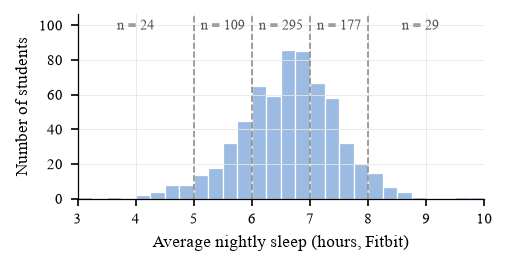

In [7]:
fig, ax = plt.subplots(figsize=(3.5, 1.6))
ax.hist(df["sleep_h"], bins=np.arange(3.0, 10.01, 0.25), color="#9bbbe3", edgecolor="white", linewidth=0.6)
for x in [5, 6, 7, 8]:
    ax.axvline(x, color=C_NEUTRAL, linestyle="--", linewidth=0.8)
ymax = ax.get_ylim()[1] * 1.18
ax.set_ylim(0, ymax)
for band, x in {"< 5 h": 4.0, "5–6 h": 5.5, "6–7 h": 6.5, "7–8 h": 7.5, "≥ 8 h": 8.9}.items():
    ax.text(x, ymax * 0.97, f"n = {band_table.loc[band, 'n']}", ha="center", va="top", color=C_TEXT, fontsize=6.5)
ax.set_xlabel("Average nightly sleep (hours, Fitbit)")
ax.set_ylabel("Number of students")
ax.set_xlim(3, 10)
save_fig(fig, "fig1_sleep_distribution")
plt.show()

About 92% of students sleep 5–8 h, so the curve is well supported there. Only 24 sleep less than 5 h and 29 sleep 8 h or more: the ends are uncertain.

## 3. The two models

$$\text{Linear:}\quad \text{GPA}_i = \beta_0 + \beta_1\,\text{Sleep}_i + \beta_2\,\text{Prev}_i + \gamma_{c(i)} + \varepsilon_i$$
$$\text{GAM:}\quad \text{GPA}_i = \beta_0 + f(\text{Sleep}_i) + \beta_2\,\text{Prev}_i + \gamma_{c(i)} + \varepsilon_i$$

Only the sleep term differs. $\beta_1$ is one slope for every hour; $f$ is a smooth curve built from 15 pieces (a *penalized spline*). GCV chooses how strongly wiggliness is penalized; a very strong penalty makes $f$ a straight line, so the GAM *allows* a curve but does not force one. The **edf** (effective degrees of freedom) says how flexible the curve is: the higher, the more it can bend. We only compare edf values (e.g. 8.3 vs 3.5); we do not read an exact edf as "straight" (in pyGAM even a straight line has an edf of about 2, because the spline term also contains a constant).

"Accounting for previous GPA" means: the sleep part is estimated as if comparing students with the same previous GPA and the same cohort.

The functions below are used for every fit in this notebook.

In [8]:
def design_matrix(d, with_cohort=True):
    # Columns: 0 = sleep (h), 1 = previous GPA, 2 = cohort code
    cols = [d["sleep_h"].to_numpy(), d["cum_gpa"].to_numpy()]
    if with_cohort:
        cols.append(pd.Categorical(d["cohort"]).codes)
    return np.column_stack(cols).astype(float)


def fit_gam(d, with_cohort=True):
    # Smooth sleep curve + previous GPA (+ cohort baselines); the penalty for sleep is chosen by GCV
    X, y = design_matrix(d, with_cohort), d["term_gpa"].to_numpy()
    terms, lam = s(0, n_splines=N_SPLINES) + l(1), [LAM_GRID, [TINY]]
    if with_cohort:
        terms, lam = terms + f(2), lam + [[TINY]]
    gam = LinearGAM(terms)
    gam.gridsearch(X, y, lam=lam, progress=False)
    return gam


def fit_linear(d, with_cohort=True):
    formula = "term_gpa ~ sleep_h + cum_gpa" + (" + C(cohort)" if with_cohort else "")
    return smf.ols(formula, data=d).fit()


def sleep_edf(gam):
    return gam.statistics_["edof_per_coef"][gam.terms.get_coef_indices(0)].sum()


def curve_gam(gam, d, hours, ref_prev_gpa):
    # Predicted GPA at each sleep value for a student with average previous GPA, averaged over cohorts
    hours = np.asarray(hours, float)
    shares = d["cohort"].value_counts(normalize=True).sort_index()
    out = np.zeros_like(hours)
    for code, share in enumerate(shares):
        X = np.column_stack([hours, np.full_like(hours, ref_prev_gpa), np.full_like(hours, code)])
        out += share * gam.predict(X)
    return out


def curve_linear(ols, d, hours, ref_prev_gpa):
    hours = np.asarray(hours, float)
    shares = d["cohort"].value_counts(normalize=True).sort_index()
    out = np.zeros_like(hours)
    for cohort, share in shares.items():
        out += share * ols.predict(pd.DataFrame({"sleep_h": hours, "cum_gpa": ref_prev_gpa, "cohort": cohort})).to_numpy()
    return out


def per_hour(gam_model, linear_model, d):
    # GPA differences for one extra hour: f(6) - f(5), f(7) - f(6), f(8) - f(7), and the key comparison
    g = np.diff(curve_gam(gam_model, d, STEPS, REF_PREV_GPA))
    return {"GAM 5→6 h": g[0], "GAM 6→7 h": g[1], "GAM 7→8 h": g[2],
            "Key comparison K = (5→6) − (7→8)": g[0] - g[2],
            "Linear: every hour": linear_model.params["sleep_h"]}

In [9]:
REF_PREV_GPA = df["cum_gpa"].mean()

lin = fit_linear(df)
coef_table = pd.DataFrame({"estimate": lin.params, "SE": lin.bse,
                           "CI 2.5%": lin.conf_int()[0], "CI 97.5%": lin.conf_int()[1]})
save_table(coef_table, "table_linear_coefficients")
print(f"Linear model: R² = {lin.rsquared:.3f}")

gam = fit_gam(df)
print(f"GAM: penalty chosen by GCV = {gam.terms[0].lam[0]:.3g}, edf of f(sleep) = {sleep_edf(gam):.2f}, "
      f"explained variance = {gam.statistics_['pseudo_r2']['explained_deviance']:.3f}")
coef_table.round(3)

Linear model: R² = 0.446
GAM: penalty chosen by GCV = 1, edf of f(sleep) = 8.31, explained variance = 0.483


,estimate,SE,CI 2.5%,CI 97.5%
Intercept,0.457,0.159,0.145,0.770
C(cohort)[T.lac2],0.098,0.054,-0.009,0.205
C(cohort)[T.nh],0.189,0.046,0.098,0.281
C(cohort)[T.uw1],0.073,0.046,-0.017,0.164
C(cohort)[T.uw2],-0.010,0.046,-0.101,0.080
sleep_h,0.093,0.018,0.057,0.130
cum_gpa,0.665,0.036,0.595,0.735


### 3b. Check against Creswell et al. (2023)
Creswell et al. reported about **0.07** GPA points per hour, using their four confirmatory cohorts (all except the discovery cohort `lac2`, 557 students) with previous GPA as covariate. If we fit that same setup, we should get the same number; this shows the data are used correctly. Our main linear model differs in two ways: it adds the discovery cohort (634 students) and gives each cohort its own baseline.

In [10]:
confirmatory = df[df["cohort"] != "lac2"]   # Creswell et al.'s confirmatory sample (557 students)
checks = {
    "Creswell setup: 557 confirmatory students, previous GPA only": smf.ols("term_gpa ~ sleep_h + cum_gpa", data=confirmatory).fit(),
    "Same 557 students + cohort baselines": smf.ols("term_gpa ~ sleep_h + cum_gpa + C(cohort)", data=confirmatory).fit(),
    "This thesis: all 634 students + cohort baselines": lin,
}
creswell_check = pd.DataFrame({name: {"n": int(m.nobs), "slope per hour": m.params["sleep_h"]}
                               for name, m in checks.items()}).T
save_table(creswell_check, "table_linear_vs_creswell")
creswell_check.round(3)

,n,slope per hour
"Creswell setup: 557 confirmatory students, previous GPA only",557.0,0.071
Same 557 students + cohort baselines,557.0,0.086
This thesis: all 634 students + cohort baselines,634.0,0.093


## 4–5. GPA differences per hour, with bootstrap uncertainty (Table II)

**Bootstrap in one sentence:** resample actual students (with replacement) within each cohort, refit both models, and see how much the estimates vary. Repeating this 1,000 times gives a 95% interval (the middle 95% of the 1,000 estimates). GCV re-chooses the smoothness every time, because that choice is also uncertain.

We report estimates **with** their intervals and look at size and uncertainty together, rather than only asking whether an interval crosses zero.

In [11]:
def estimates(d):
    g, o = fit_gam(d), fit_linear(d)
    row = per_hour(g, o, d)
    row["edf"] = sleep_edf(g)
    return row, curve_gam(g, d, GRID, REF_PREV_GPA), curve_linear(o, d, GRID, REF_PREV_GPA)


def stratified_bootstrap(d, label, n_boot=B, seed=SEED):
    name = (f"bootstrap_{label}_B{n_boot}_seed{seed}_ns{N_SPLINES}_lam{len(LAM_GRID)}"
            f"_grid{round(GRID.min() * 10)}-{round(GRID.max() * 10)}x{len(GRID)}")
    csv_path, npz_path = CACHE / f"{name}.csv", CACHE / f"{name}.npz"
    if USE_CACHE and csv_path.exists() and npz_path.exists():
        saved = np.load(npz_path)
        print(f"Loaded cached bootstrap '{label}'.")
        return pd.read_csv(csv_path), saved["gam_curves"], saved["lin_curves"]
    rng = np.random.default_rng(seed)
    d = d.reset_index(drop=True)
    groups = [np.flatnonzero(d["cohort"].to_numpy() == c) for c in sorted(d["cohort"].unique())]
    rows, gam_curves, lin_curves = [], [], []
    for b in range(n_boot):
        idx = np.concatenate([rng.choice(g, size=len(g), replace=True) for g in groups])
        row, gc, lc = estimates(d.iloc[idx])
        rows.append(row); gam_curves.append(gc); lin_curves.append(lc)
        if (b + 1) % 100 == 0:
            print(f"  {label}: {b + 1}/{n_boot}")
    boot = pd.DataFrame(rows)
    boot.to_csv(csv_path, index=False)
    np.savez(npz_path, gam_curves=np.array(gam_curves), lin_curves=np.array(lin_curves))
    return boot, np.array(gam_curves), np.array(lin_curves)


def ci_table(point_est, boot):
    cols = list(point_est.index)
    return pd.DataFrame({"estimate": point_est,
                         "CI 2.5%": boot[cols].quantile(0.025),
                         "CI 97.5%": boot[cols].quantile(0.975),
                         "% of bootstrap samples > 0": 100 * (boot[cols] > 0).mean()})


point_main = pd.Series(per_hour(gam, lin, df))
boot_main, gam_curves, lin_curves = stratified_bootstrap(df, "main")
diff_main = ci_table(point_main, boot_main)
diff_main.round(3)

  main: 100/1000
  main: 200/1000
  main: 300/1000
  main: 400/1000
  main: 500/1000
  main: 600/1000
  main: 700/1000
  main: 800/1000
  main: 900/1000
  main: 1000/1000


,estimate,CI 2.5%,CI 97.5%,% of bootstrap samples > 0
GAM 5→6 h,0.176,0.003,0.442,97.5
GAM 6→7 h,0.060,-0.023,0.137,91.9
GAM 7→8 h,-0.027,-0.139,0.072,32.9
Key comparison K = (5→6) − (7→8),0.202,0.000,0.526,97.6
Linear: every hour,0.093,0.048,0.144,100.0


**How to read this:** each number is a GPA difference on the 0–4 scale (0.10 = one tenth of a grade point). In the linear model every hour has the same difference by definition. The key comparison $K$ is the 5→6 h difference minus the 7→8 h difference: positive means the association is stronger at shorter sleep.

## 6. Sensitivity analysis: without the two students who sleep less than 4 h

Two students sleep 3.25 and 3.66 h; the next lowest sleeps 4.17 h. Both have a very low term GPA. GCV chooses **one** smoothness for the whole curve, so a few extreme students at one end can make the whole curve more wiggly. We therefore repeat the full analysis (models + bootstrap) without them.

In [12]:
print(df.loc[df["sleep_h"] < 4, ["cohort", "sleep_h", "cum_gpa", "term_gpa"]].round(2))

d_trim = df[df["sleep_h"] >= 4]
gam_trim, lin_trim = fit_gam(d_trim), fit_linear(d_trim)
point_trim = pd.Series(per_hour(gam_trim, lin_trim, d_trim))
boot_trim, _, _ = stratified_bootstrap(d_trim, "without_below4h")
diff_trim = ci_table(point_trim, boot_trim)
print(f"edf without them: {sleep_edf(gam_trim):.2f} (with them: {sleep_edf(gam):.2f})")

table2 = pd.concat({"All students (n = 634)": diff_main,
                    f"Without sleep < 4 h (n = {len(d_trim)})": diff_trim}, axis=1)
save_table(table2, "table2_per_hour_differences")
table2.round(3)

    cohort  sleep_h  cum_gpa  term_gpa
258   lac2     3.66     2.78      1.50
470    uw2     3.25     2.95      1.07
  without_below4h: 100/1000
  without_below4h: 200/1000
  without_below4h: 300/1000
  without_below4h: 400/1000
  without_below4h: 500/1000
  without_below4h: 600/1000
  without_below4h: 700/1000
  without_below4h: 800/1000
  without_below4h: 900/1000
  without_below4h: 1000/1000
edf without them: 3.48 (with them: 8.31)


All students (n = 634)                   \
                                               estimate CI 2.5% CI 97.5%   
GAM 5→6 h                                         0.176   0.003    0.442   
GAM 6→7 h                                         0.060  -0.023    0.137   
GAM 7→8 h                                        -0.027  -0.139    0.072   
Key comparison K = (5→6) − (7→8)                  0.202   0.000    0.526   
Linear: every hour                                0.093   0.048    0.144   

                                                             \
                                 % of bootstrap samples > 0   
GAM 5→6 h                                              97.5   
GAM 6→7 h                                              91.9   
GAM 7→8 h                                              32.9   
Key comparison K = (5→6) − (7→8)                       97.6   
Linear: every hour                                    100.0   

                                 Without sleep < 4 h (n = 632)          \
                                                      estimate CI 2.5%   
GAM 5→6 h                                                0.137   0.019   
GAM 6→7 h                                                0.070  -0.033   
GAM 7→8 h                                                0.019  -0.147   
Key comparison K = (5→6) − (7→8)                         0.119  -0.000   
Linear: every hour                                       0.071   0.031   

                                                                      
                                 CI 97.5% % of bootstrap samples > 0  
GAM 5→6 h                           0.469                       98.4  
GAM 6→7 h                           0.126                       92.8  
GAM 7→8 h                           0.089                       47.7  
Key comparison K = (5→6) − (7→8)    0.540                       96.3  
Linear: every hour                  0.117                      100.0

### 6a. Why are both lower bounds of K about zero?
The GAM is *allowed* to become a straight line. In some bootstrap samples GCV picks one of the strongest penalties; the curve is then (almost) straight, and for a straight line every hour has the same difference, so K = 0 by construction. The table below splits the 1,000 bootstrap values of K into clearly negative, about zero and clearly positive. The lower bound of a 95% interval is the value below which 2.5% of the samples lie. Fewer than 2.5% are clearly negative in both analyses, so both lower bounds fall among the "about zero" samples. That is why they are both about zero and why their sign does not matter.

The first line printed is the edf pyGAM reports for a practically straight line (the reference value mentioned in Methods III-C).

In [13]:
K_NAME = "Key comparison K = (5→6) − (7→8)"
ZERO = 0.005        # |K| below this is 0.00 when rounded to two decimals

# Reference value: the edf of f(sleep) when the penalty is the largest in the grid (a practically straight line)
straight = LinearGAM(s(0, n_splines=N_SPLINES, lam=LAM_GRID.max()) + l(1, lam=TINY) + f(2, lam=TINY))
straight.fit(design_matrix(df), df["term_gpa"].to_numpy())
print(f"edf of f(sleep) for a practically straight line: {sleep_edf(straight):.2f}")


def k_split(boot):
    k = boot[K_NAME]
    about_zero = k.abs() < ZERO
    return pd.Series({
        "K clearly negative (%)": 100 * (k <= -ZERO).mean(),
        "K about zero (%)": 100 * about_zero.mean(),
        "  of which almost straight line, edf < 2.5 (%)": 100 * (about_zero & (boot["edf"] < 2.5)).mean(),
        "K clearly positive (%)": 100 * (k >= ZERO).mean(),
    })


table_k = pd.DataFrame({"All students (n = 634)": k_split(boot_main),
                        f"Without sleep < 4 h (n = {len(d_trim)})": k_split(boot_trim)})
save_table(table_k, "table_bootstrap_K_split")
table_k.round(1)

edf of f(sleep) for a practically straight line: 2.12


,All students (n = 634),Without sleep < 4 h (n = 632)
K clearly negative (%),1.7,1.8
K about zero (%),1.9,9.1
"of which almost straight line, edf < 2.5 (%)",1.2,9.0
K clearly positive (%),96.4,89.1


### Fig. 2: the adjusted curves (main result)
Predicted GPA for a student with average previous GPA (averaged over cohorts in proportion to their size), with 95% bootstrap bands. Dashed: GAM without the two students below 4 h. This curve is the main result; the one-hour differences in Table II summarize it in numbers. Small bumps (the dip near 7.7 h, the upturn above 8 h) are not interpreted: the dip disappears without the two shortest sleepers, and few students sleep more than 8 h.

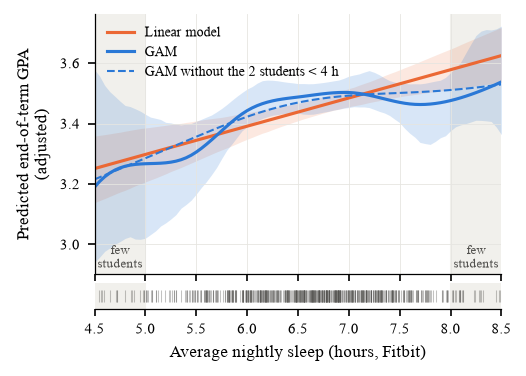

In [14]:
gam_curve = curve_gam(gam, df, GRID, REF_PREV_GPA)
lin_curve = curve_linear(lin, df, GRID, REF_PREV_GPA)
g_lo, g_hi = np.percentile(gam_curves, [2.5, 97.5], axis=0)
l_lo, l_hi = np.percentile(lin_curves, [2.5, 97.5], axis=0)

fig, (ax, rug) = plt.subplots(2, 1, figsize=(3.5, 2.55), sharex=True,
                              gridspec_kw={"height_ratios": [6, 0.6], "hspace": 0.06})
for a in (ax, rug):
    a.axvspan(GRID.min(), 5, color=C_SPARSE, zorder=0)
    a.axvspan(8, GRID.max(), color=C_SPARSE, zorder=0)
ax.fill_between(GRID, l_lo, l_hi, color=C_LIN, alpha=0.15, linewidth=0)
ax.fill_between(GRID, g_lo, g_hi, color=C_GAM, alpha=0.18, linewidth=0)
ax.plot(GRID, lin_curve, color=C_LIN, linewidth=1.5, label="Linear model")
ax.plot(GRID, gam_curve, color=C_GAM, linewidth=1.5, label="GAM")
ax.plot(GRID, curve_gam(gam_trim, d_trim, GRID, REF_PREV_GPA), color=C_GAM, linewidth=1.0,
        linestyle="--", label="GAM without the 2 students < 4 h")
y_text = ax.get_ylim()[0] + 0.01
ax.text((GRID.min() + 5) / 2, y_text, "few\nstudents", ha="center", va="bottom", color=C_TEXT, fontsize=6)
ax.text((8 + GRID.max()) / 2, y_text, "few\nstudents", ha="center", va="bottom", color=C_TEXT, fontsize=6)
ax.set_ylabel("Predicted end-of-term GPA\n(adjusted)")
ax.legend(loc="upper left", frameon=False, fontsize=6.5)
in_range = df["sleep_h"].between(GRID.min(), GRID.max())
rug.plot(df.loc[in_range, "sleep_h"], np.zeros(in_range.sum()), "|", color=C_TEXT, alpha=0.35,
         markersize=6, markeredgewidth=0.5)
rug.set_yticks([]); rug.grid(False); rug.spines["left"].set_visible(False)
rug.set_xlabel("Average nightly sleep (hours, Fitbit)")
rug.set_xlim(GRID.min(), GRID.max())
save_fig(fig, "fig2_adjusted_curves")
plt.show()

## 6b. Residual check: where does the straight line miss?
A **residual** is a student's actual GPA minus the GPA the model predicts. If a model has the right shape, its residuals average about 0 at every sleep level. We average the residuals of both models per half-hour of sleep. The two outer bins are open-ended: the first is everything below 4.5 h (including the two students below 4 h), the last everything from 8.5 h (including the two students above 9 h). The middle bins, which the report cites, are exact half-hours and add a 95% interval (mean ± 1.96 × standard error). This is the "check whether the models' errors show patterns" step from the poster.

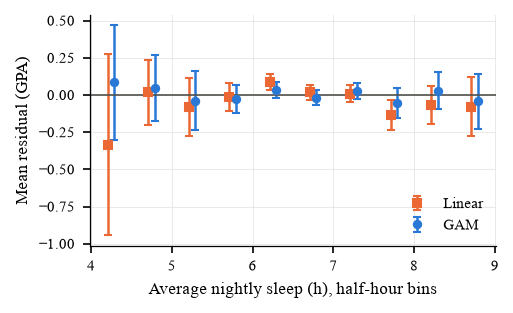

n Linear                     GAM                 
           sleep_h   mean CI 2.5% CI 97.5%   mean CI 2.5% CI 97.5%
sleep_bin                                                         
[4.0, 4.5)       8 -0.335  -0.943    0.273  0.084  -0.300    0.468
[4.5, 5.0)      16  0.017  -0.203    0.236  0.046  -0.174    0.267
[5.0, 5.5)      32 -0.082  -0.278    0.114 -0.038  -0.234    0.158
[5.5, 6.0)      77 -0.015  -0.108    0.077 -0.028  -0.121    0.065
[6.0, 6.5)     124  0.089   0.037    0.142  0.034  -0.019    0.086
[6.5, 7.0)     171  0.018  -0.033    0.069 -0.019  -0.070    0.032
[7.0, 7.5)     125  0.009  -0.048    0.067  0.027  -0.030    0.084
[7.5, 8.0)      52 -0.136  -0.236   -0.036 -0.051  -0.152    0.049
[8.0, 8.5)      22 -0.065  -0.193    0.062  0.030  -0.097    0.157
[8.5, 9.0)       7 -0.080  -0.279    0.118 -0.042  -0.227    0.143

In [15]:
df["resid_linear"] = lin.resid
df["resid_gam"] = df["term_gpa"] - gam.predict(design_matrix(df))
# Outer bins are open-ended: values below 4 h go into the first bin (< 4.5 h), values of 9 h or more into the last (≥ 8.5 h)
df["sleep_bin"] = pd.cut(df["sleep_h"].clip(4.0, 8.999), np.arange(4.0, 9.01, 0.5), right=False)

def mean_ci(r):
    se = r.std() / np.sqrt(len(r))
    return pd.Series({"mean": r.mean(), "CI 2.5%": r.mean() - 1.96 * se, "CI 97.5%": r.mean() + 1.96 * se})

resid_table = pd.concat({
    "n": df.groupby("sleep_bin", observed=True)["sleep_h"].size(),
    "Linear": df.groupby("sleep_bin", observed=True)["resid_linear"].apply(mean_ci).unstack(),
    "GAM": df.groupby("sleep_bin", observed=True)["resid_gam"].apply(mean_ci).unstack(),
}, axis=1)
bin_labels = ["< 4.5 h" if k == 0 else "≥ 8.5 h" if k == len(resid_table) - 1 else f"{iv.left:.1f}–{iv.right:.1f} h"
              for k, iv in enumerate(resid_table.index)]
save_table(resid_table.set_axis(bin_labels), "table_residuals_by_sleep")

fig, ax = plt.subplots(figsize=(3.5, 2.0))
mid = np.array([iv.mid for iv in resid_table.index])
for model, colour, marker, shift in [("Linear", C_LIN, "s", -0.04), ("GAM", C_GAM, "o", 0.04)]:
    t = resid_table[model]
    ax.errorbar(mid + shift, t["mean"], yerr=[t["mean"] - t["CI 2.5%"], t["CI 97.5%"] - t["mean"]],
                fmt=marker, color=colour, capsize=2, markersize=3.5, label=model)
ax.axhline(0, color=C_TEXT, linewidth=0.8)
ax.set_xlabel("Average nightly sleep (h), half-hour bins"); ax.set_ylabel("Mean residual (GPA)")
ax.legend(frameon=False, loc="lower right")
save_fig(fig, "fig_extra_residuals")
plt.show()
resid_table.round(3)

**How to read it:** where the orange squares sit clearly above 0, the straight line predicts too low; clearly below 0, too high. The linear model predicts too low around 6–6.5 h and too high around 7.5–8 h, which is consistent with a curve that flattens; the GAM's residuals in those bins are closer to 0. This is a descriptive check, because both models were fitted to the same data.

## 7. Does the pattern depend on one cohort? (Fig. 3)
The GAM is refitted five times, each time without one cohort. Curves are shown relative to 7 h so their shapes can be compared.

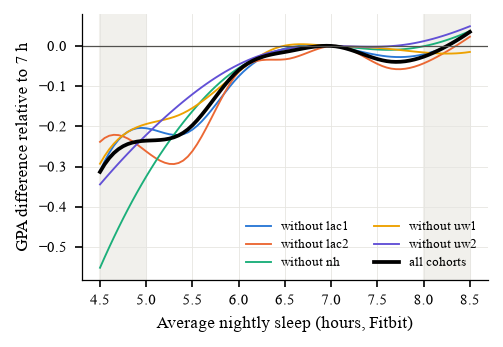

,GAM 5→6 h,GAM 6→7 h,GAM 7→8 h,Key comparison K = (5→6) − (7→8),Linear: every hour,n
without lac1,0.129,0.076,-0.021,0.150,0.101,503.0
without lac2,0.198,0.065,-0.043,0.241,0.086,557.0
without nh,0.270,0.055,-0.001,0.271,0.108,487.0
without uw1,0.131,0.064,-0.016,0.147,0.094,494.0
without uw2,0.175,0.046,0.012,0.163,0.079,495.0


In [16]:
def relative_to_7(gam_model, d):
    vals = curve_gam(gam_model, d, np.r_[GRID, 7.0], d["cum_gpa"].mean())
    return vals[:-1] - vals[-1]

loco_rows = {}
fig, ax = plt.subplots(figsize=(3.5, 2.3))
ax.axvspan(GRID.min(), 5, color=C_SPARSE, zorder=0); ax.axvspan(8, GRID.max(), color=C_SPARSE, zorder=0)
for colour, cohort in zip(C_COHORTS, sorted(df["cohort"].unique())):
    d = df[df["cohort"] != cohort]
    g, o = fit_gam(d), fit_linear(d)
    loco_rows[f"without {cohort}"] = {**per_hour(g, o, d), "n": len(d)}
    ax.plot(GRID, relative_to_7(g, d), color=colour, linewidth=0.9, label=f"without {cohort}")
ax.plot(GRID, relative_to_7(gam, df), color="black", linewidth=1.8, label="all cohorts")
ax.axhline(0, color=C_TEXT, linewidth=0.6)
ax.set_xlabel("Average nightly sleep (hours, Fitbit)")
ax.set_ylabel("GPA difference relative to 7 h")
ax.legend(frameon=False, ncol=2, fontsize=6, loc="lower right")
save_fig(fig, "fig3_leave_one_cohort_out")
plt.show()

table_loco = pd.DataFrame(loco_rows).T
save_table(table_loco, "table_leave_one_cohort_out")
table_loco.round(3)

## 8. Secondary check: prediction for an unseen cohort
Fit on four cohorts, predict the GPA of the fifth, repeat for every cohort. No cohort baselines (an unseen cohort's baseline is unknown). Baselines for comparison: predicting the average GPA, and previous GPA only. **MAE** = average size of an error (GPA points); **RMSE** = similar, but large errors count more.

In [17]:
rows = []
for cohort in sorted(df["cohort"].unique()):
    train, test = df[df["cohort"] != cohort], df[df["cohort"] == cohort]
    preds = {
        "Mean only": np.full(len(test), train["term_gpa"].mean()),
        "Previous GPA only": smf.ols("term_gpa ~ cum_gpa", data=train).fit().predict(test).to_numpy(),
        "Linear (sleep + prev. GPA)": fit_linear(train, with_cohort=False).predict(test).to_numpy(),
        "GAM (sleep + prev. GPA)": fit_gam(train, with_cohort=False).predict(design_matrix(test, with_cohort=False)),
    }
    for model, p in preds.items():
        err = test["term_gpa"].to_numpy() - p
        rows.append({"left-out cohort": cohort, "model": model,
                     "MAE": np.abs(err).mean(), "RMSE": np.sqrt((err ** 2).mean())})
pred = pd.DataFrame(rows)
order = list(preds.keys())
table_pred = pd.concat({m: pred.pivot(index="left-out cohort", columns="model", values=m)[order]
                        for m in ["MAE", "RMSE"]}, axis=1)
table_pred.loc["Mean over 5 cohorts"] = table_pred.mean()
save_table(table_pred, "table_prediction_across_cohorts")
table_pred.round(3)

MAE                                               \
model               Mean only Previous GPA only Linear (sleep + prev. GPA)   
left-out cohort                                                              
lac1                    0.444             0.367                      0.363   
lac2                    0.387             0.300                      0.294   
nh                      0.344             0.193                      0.206   
uw1                     0.351             0.257                      0.248   
uw2                     0.392             0.301                      0.298   
Mean over 5 cohorts     0.384             0.284                      0.282   

                                                 RMSE                    \
model               GAM (sleep + prev. GPA) Mean only Previous GPA only   
left-out cohort                                                           
lac1                                  0.365     0.611             0.488   
lac2                                  0.289     0.508             0.411   
nh                                    0.204     0.386             0.231   
uw1                                   0.245     0.450             0.359   
uw2                                   0.294     0.587             0.442   
Mean over 5 cohorts                   0.279     0.509             0.386   

                                                                        
model               Linear (sleep + prev. GPA) GAM (sleep + prev. GPA)  
left-out cohort                                                         
lac1                                     0.485                   0.486  
lac2                                     0.398                   0.381  
nh                                       0.251                   0.261  
uw1                                      0.349                   0.346  
uw2                                      0.434                   0.424  
Mean over 5 cohorts                      0.383                   0.380

## 9. Summary (numbers used in the report)

In [18]:
def fmt(t, k):
    r = t.loc[k]
    return f"{r['estimate']:.3f} [{r['CI 2.5%']:.3f}, {r['CI 97.5%']:.3f}]  ({r['% of bootstrap samples > 0']:.1f}% > 0)"

for title, t, g in [("ALL STUDENTS (n = 634)", diff_main, gam), (f"WITHOUT SLEEP < 4 h (n = {len(d_trim)})", diff_trim, gam_trim)]:
    print(title, f"   edf = {sleep_edf(g):.2f}")
    for k in t.index:
        print(f"  {k:<36}{fmt(t, k)}")
    print()
k = "Key comparison K = (5→6) − (7→8)"
print(f"Leave one cohort out: K ranges from {table_loco[k].min():.3f} to {table_loco[k].max():.3f}")
print()
print("Prediction for unseen cohorts (mean over 5 cohorts):")
print(table_pred.loc["Mean over 5 cohorts"].unstack(0).round(3).to_string())

ALL STUDENTS (n = 634)    edf = 8.31
  GAM 5→6 h                           0.176 [0.003, 0.442]  (97.5% > 0)
  GAM 6→7 h                           0.060 [-0.023, 0.137]  (91.9% > 0)
  GAM 7→8 h                           -0.027 [-0.139, 0.072]  (32.9% > 0)
  Key comparison K = (5→6) − (7→8)    0.202 [0.000, 0.526]  (97.6% > 0)
  Linear: every hour                  0.093 [0.048, 0.144]  (100.0% > 0)

WITHOUT SLEEP < 4 h (n = 632)    edf = 3.48
  GAM 5→6 h                           0.137 [0.019, 0.469]  (98.4% > 0)
  GAM 6→7 h                           0.070 [-0.033, 0.126]  (92.8% > 0)
  GAM 7→8 h                           0.019 [-0.147, 0.089]  (47.7% > 0)
  Key comparison K = (5→6) − (7→8)    0.119 [-0.000, 0.540]  (96.3% > 0)
  Linear: every hour                  0.071 [0.031, 0.117]  (100.0% > 0)

Leave one cohort out: K ranges from 0.147 to 0.271

Prediction for unseen cohorts (mean over 5 cohorts):
                              MAE   RMSE
model                                   
Me

### What this means (and what it does not)
- **Shape (Fig. 2):** the fitted GAM curve rises more steeply at shorter sleep durations and flattens toward 7–8 h, whereas a straight line gives about 0.09 GPA points to every hour. This is a visual description of the fitted curve; it does not locate a threshold. The numbers we actually calculate are the one-hour differences below.
- **In numbers (Table II), between 5 and 8 h where most students are:** 5→6 h about 0.18; 7→8 h an estimate near zero, with an interval that includes negative and positive differences. Key comparison K = 0.20.
- **How certain:** the *direction* of K is stable: it stays positive without the two shortest sleepers and when each cohort is left out in turn. The *size* is not: K falls from 0.20 to 0.12 without the two students, and both intervals are wide, with lower bounds at about zero (step 6a: in some bootstrap samples the GAM becomes an almost straight line, for which K = 0; the exact sign of the bounds is not meaningful). So: suggestive evidence of a flattening, with an uncertain magnitude.
- **Cohorts:** K stays positive whichever cohort is left out (0.15 to 0.27), although the curves differ in detail. This is not a separate curve per cohort.
- **Creswell check (step 3b):** with their sample and covariate the code reproduces their slope (0.071); the higher 0.093 here comes from adding the discovery cohort and cohort baselines.
- **Prediction:** previous GPA does most of the predicting; adding sleep (as a line or a curve) improves predictions for unseen cohorts only a little.
- **Not claimed:** cause and effect, an "optimal" amount of sleep, whether the change is gradual or a sharp threshold (a GAM is smooth by design), or anything below 5 h or above 8 h.
